In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns',None)
pd.set_option("display.max_rows",None)
import warnings
warnings.filterwarnings("ignore")

###Reading Data

In [3]:
df=pd.read_csv(r'/content/Airline_customer_satisfaction.csv',encoding="latin-1")

In [4]:
df.head()

,satisfaction,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,Inflight wifi service,Inflight entertainment,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
0,satisfied,Loyal Customer,65,Personal Travel,Eco,265,0,0,0,2,2,4,2,3,3,0,3,5,3,2,0,0.0
1,satisfied,Loyal Customer,47,Personal Travel,Business,2464,0,0,0,3,0,2,2,3,4,4,4,2,3,2,310,305.0
2,satisfied,Loyal Customer,15,Personal Travel,Eco,2138,0,0,0,3,2,0,2,2,3,3,4,4,4,2,0,0.0
3,satisfied,Loyal Customer,60,Personal Travel,Eco,623,0,0,0,3,3,4,3,1,1,0,1,4,1,3,0,0.0
4,satisfied,Loyal Customer,70,Personal Travel,Eco,354,0,0,0,3,4,3,4,2,2,0,2,4,2,5,0,0.0


In [5]:
df.tail()

,satisfaction,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,Inflight wifi service,Inflight entertainment,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
129875,satisfied,disloyal Customer,29,Personal Travel,Eco,1731,5,5,5,3,2,5,2,2,3,3,4,4,4,2,0,0.0
129876,dissatisfied,disloyal Customer,63,Personal Travel,Business,2087,2,3,2,4,2,1,1,3,2,3,3,1,2,1,174,172.0
129877,dissatisfied,disloyal Customer,69,Personal Travel,Eco,2320,3,0,3,3,3,2,2,4,4,3,4,2,3,2,155,163.0
129878,dissatisfied,disloyal Customer,66,Personal Travel,Eco,2450,3,2,3,2,3,2,2,3,3,2,3,2,1,2,193,205.0
129879,dissatisfied,disloyal Customer,38,Personal Travel,Eco,4307,3,4,3,3,3,3,3,4,5,5,5,3,3,3,185,186.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   satisfaction                       129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Seat comfort                       129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Food and drink                     129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Inflight wifi service              129880 non-null  int64  
 11  Inflight entertainment             1298

In [7]:
print("missing values:")
df.isnull().sum().sort_values(ascending=False)

missing values:


,0
Arrival Delay in Minutes,393
satisfaction,0
Age,0
Type of Travel,0
Class,0
Customer Type,0
Flight Distance,0
Seat comfort,0
Food and drink,0
Departure/Arrival time convenient,0


In [8]:
df.nunique()

,0
satisfaction,2
Customer Type,2
Age,75
Type of Travel,2
Class,3
Flight Distance,5398
Seat comfort,6
Departure/Arrival time convenient,6
Food and drink,6
Gate location,6


In [9]:
cols=["Type of Travel","Class","Customer Type"]
for col in cols:
   print(col,":",df[col].unique())

Type of Travel : ['Personal Travel' 'Business travel']
Class : ['Eco' 'Business' 'Eco Plus']
Customer Type : ['Loyal Customer' 'disloyal Customer']


In [10]:
df_new=df.drop("satisfaction",axis=1)

###Data Analysis

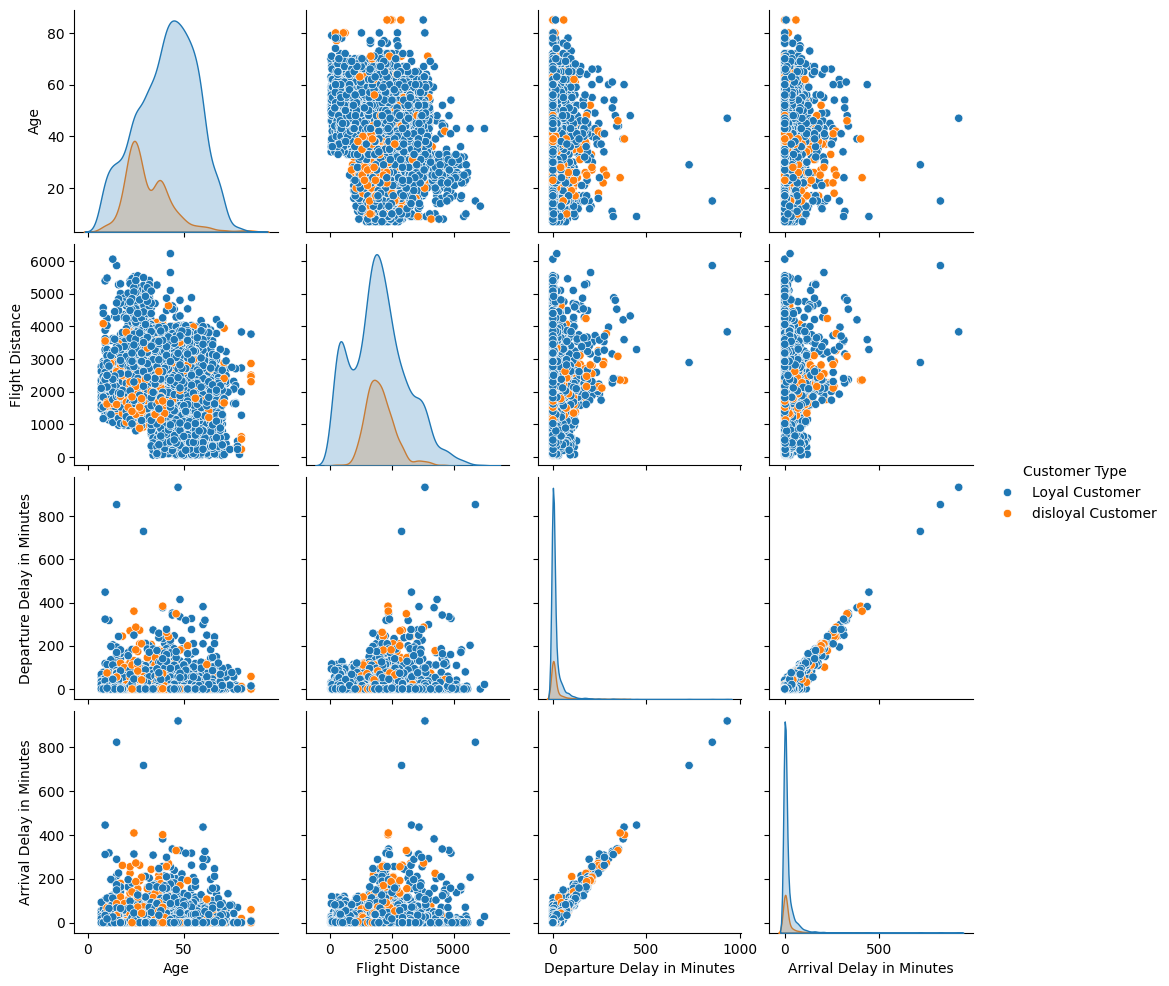

In [11]:
cols=['Age','Flight Distance','Departure Delay in Minutes','Arrival Delay in Minutes',"Customer Type"]
df_sample = df_new[cols].sample(n=min(5000, len(df_new)),random_state=42)

sns.pairplot(df_sample,hue="Customer Type")
plt.show()

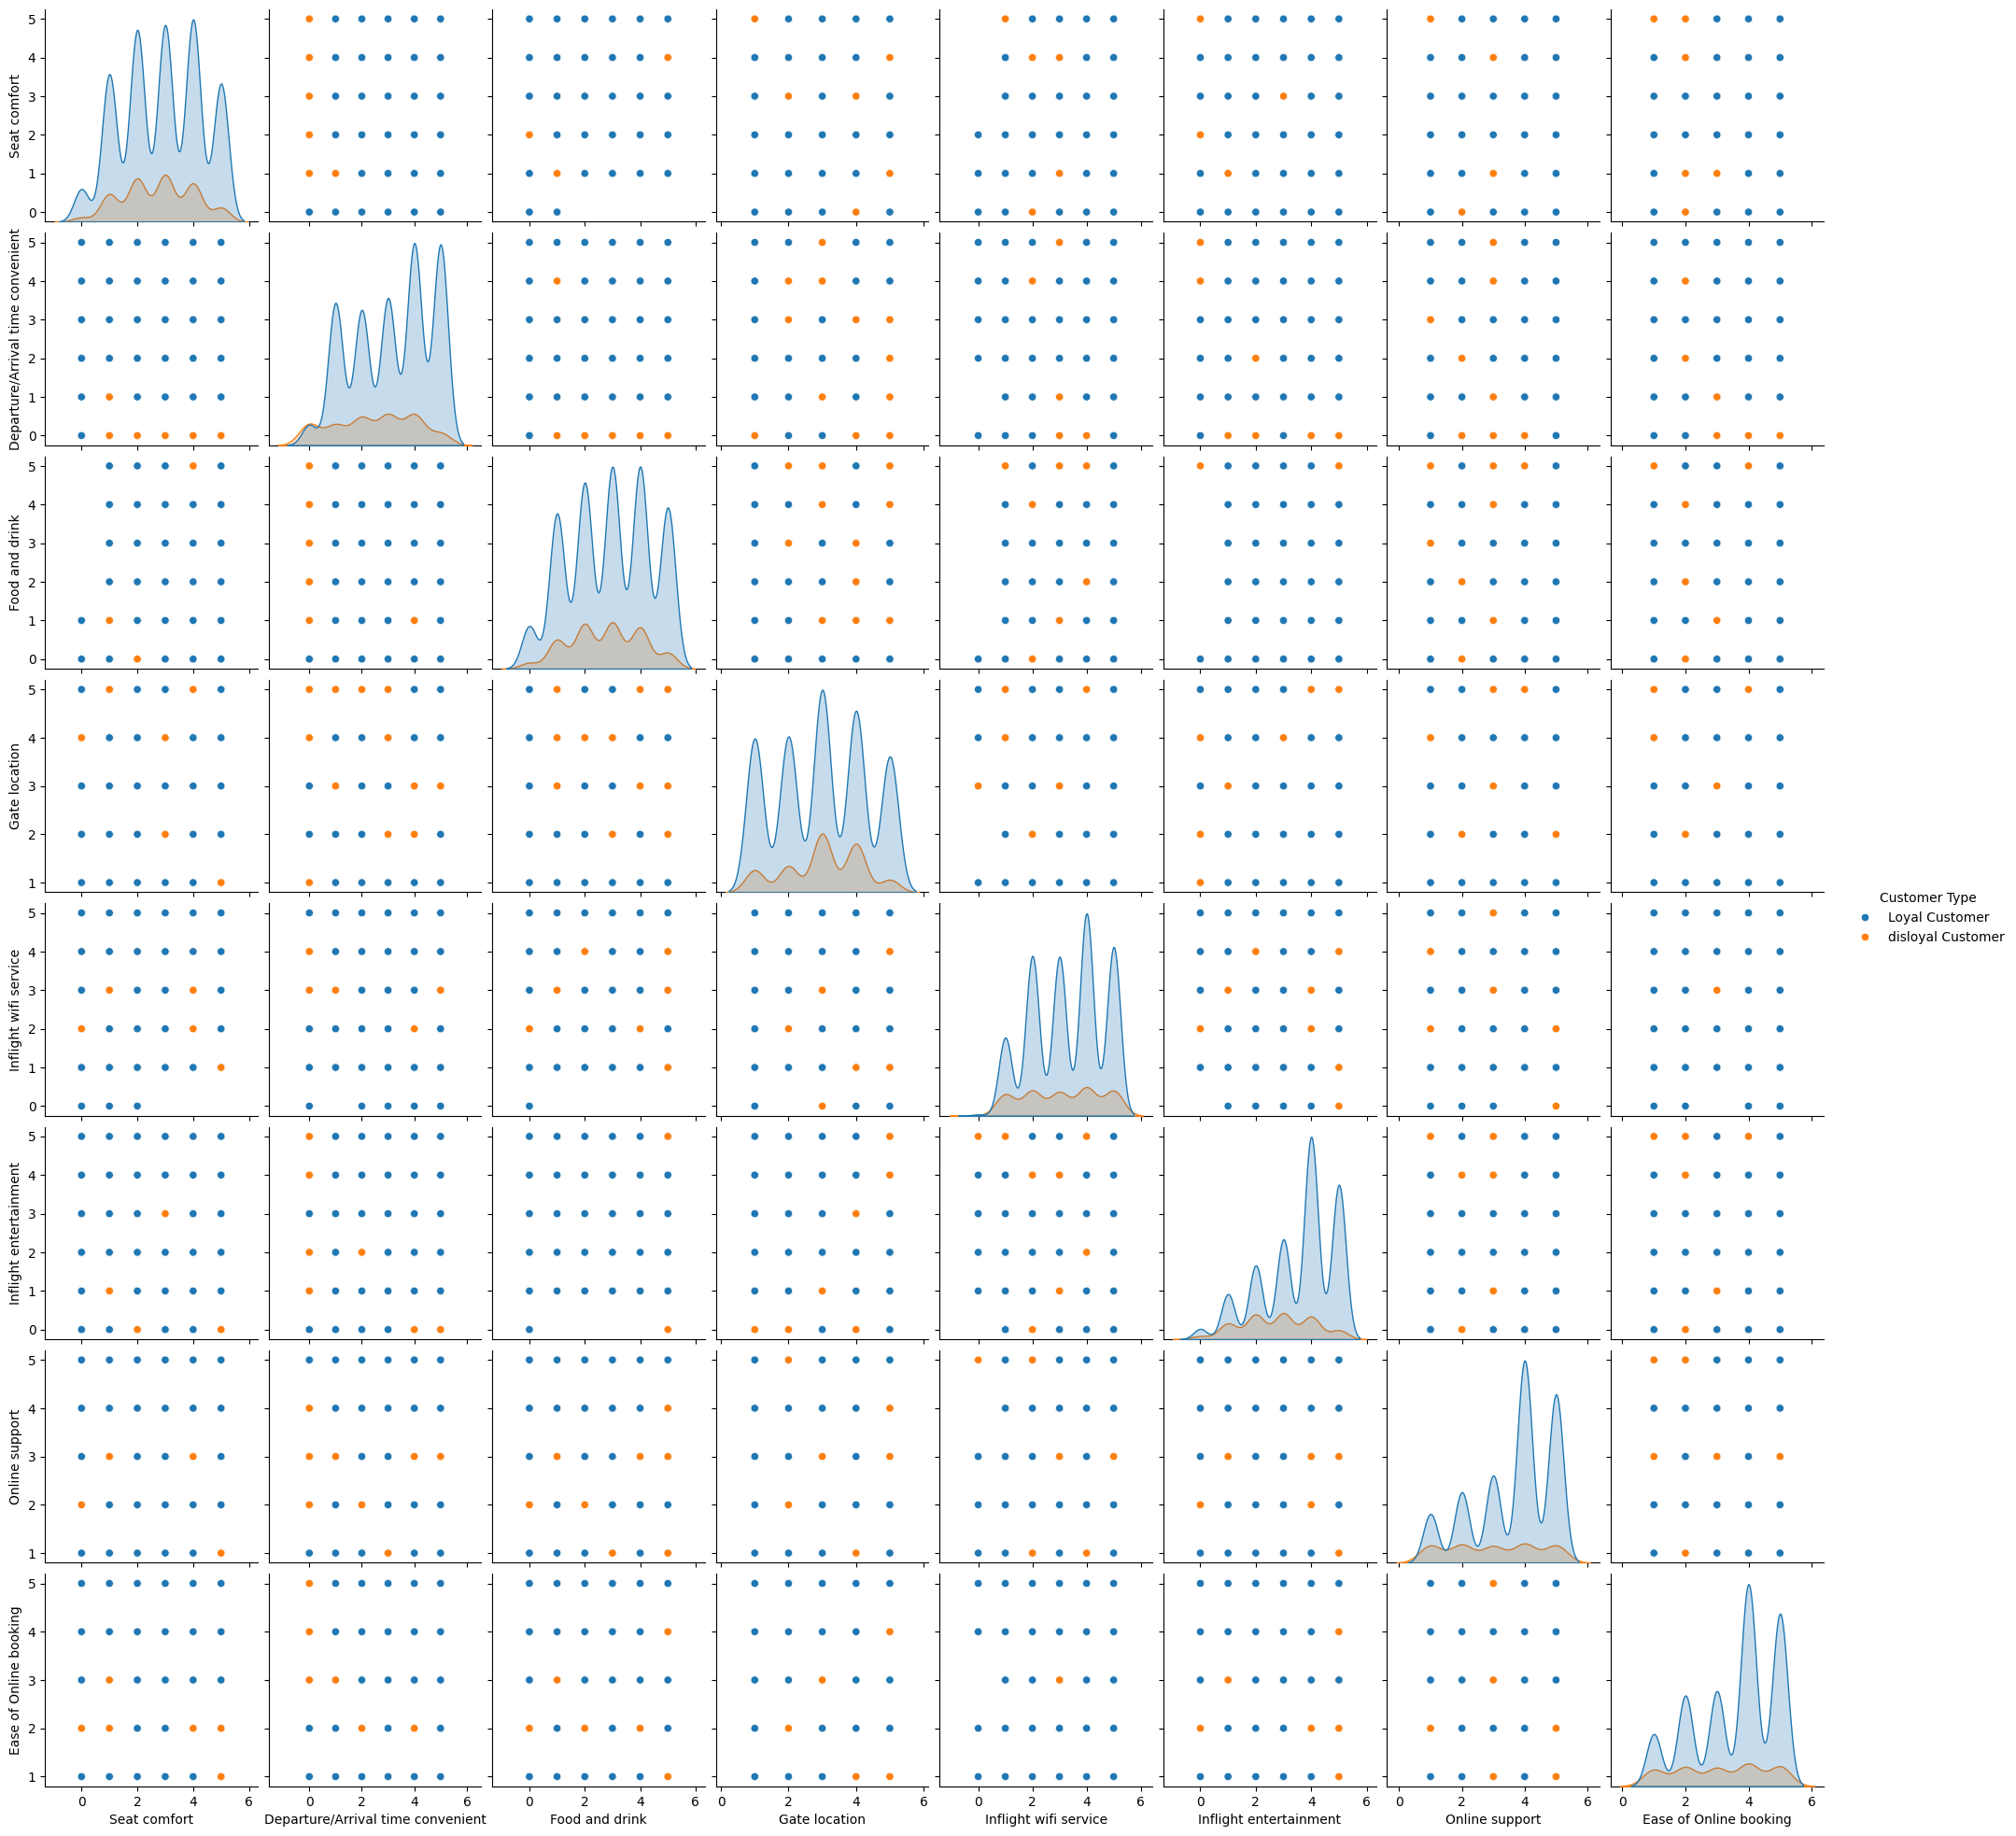

In [12]:
cols=["Customer Type","Seat comfort","Departure/Arrival time convenient","Food and drink","Gate location","Inflight wifi service","Inflight entertainment","Online support","Ease of Online booking"]
df_sample = df_new[cols].sample(n=min(5000, len(df_new)),random_state=42)

sns.pairplot(df_sample,hue="Customer Type")
plt.show()

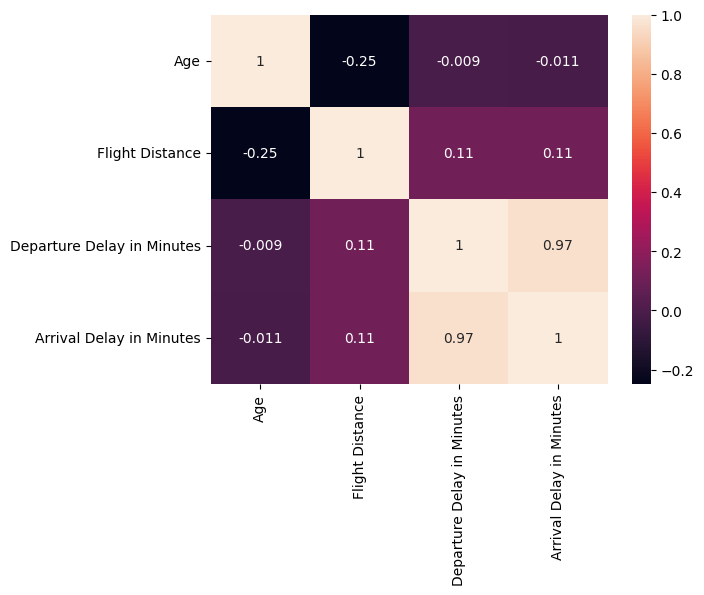

In [13]:
cols=['Age','Flight Distance','Departure Delay in Minutes','Arrival Delay in Minutes']
sns.heatmap(df_new[cols].corr(),annot=True)
plt.show()

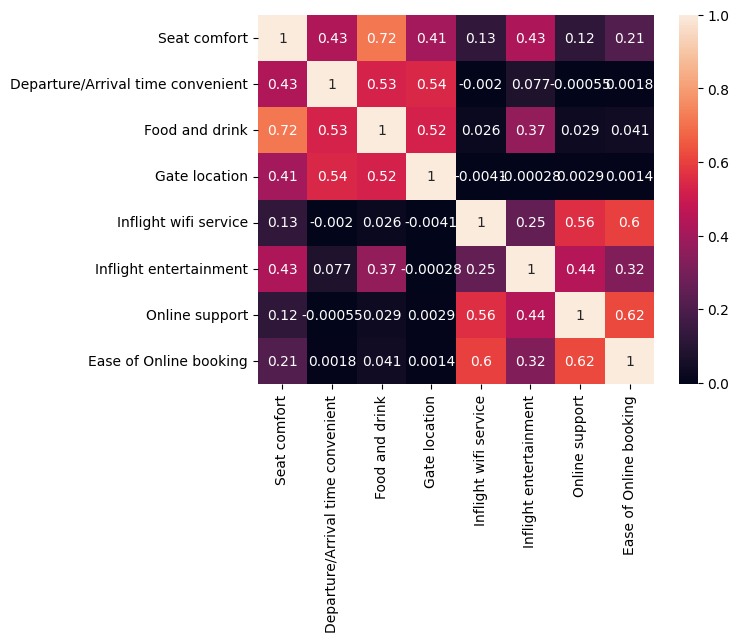

<Figure size 1500x1500 with 0 Axes>

In [14]:
cols=["Seat comfort","Departure/Arrival time convenient","Food and drink","Gate location","Inflight wifi service","Inflight entertainment","Online support","Ease of Online booking"]
sns.heatmap(df_new[cols].corr(),annot=True)
plt.figure(figsize=(15,15))
plt.show()

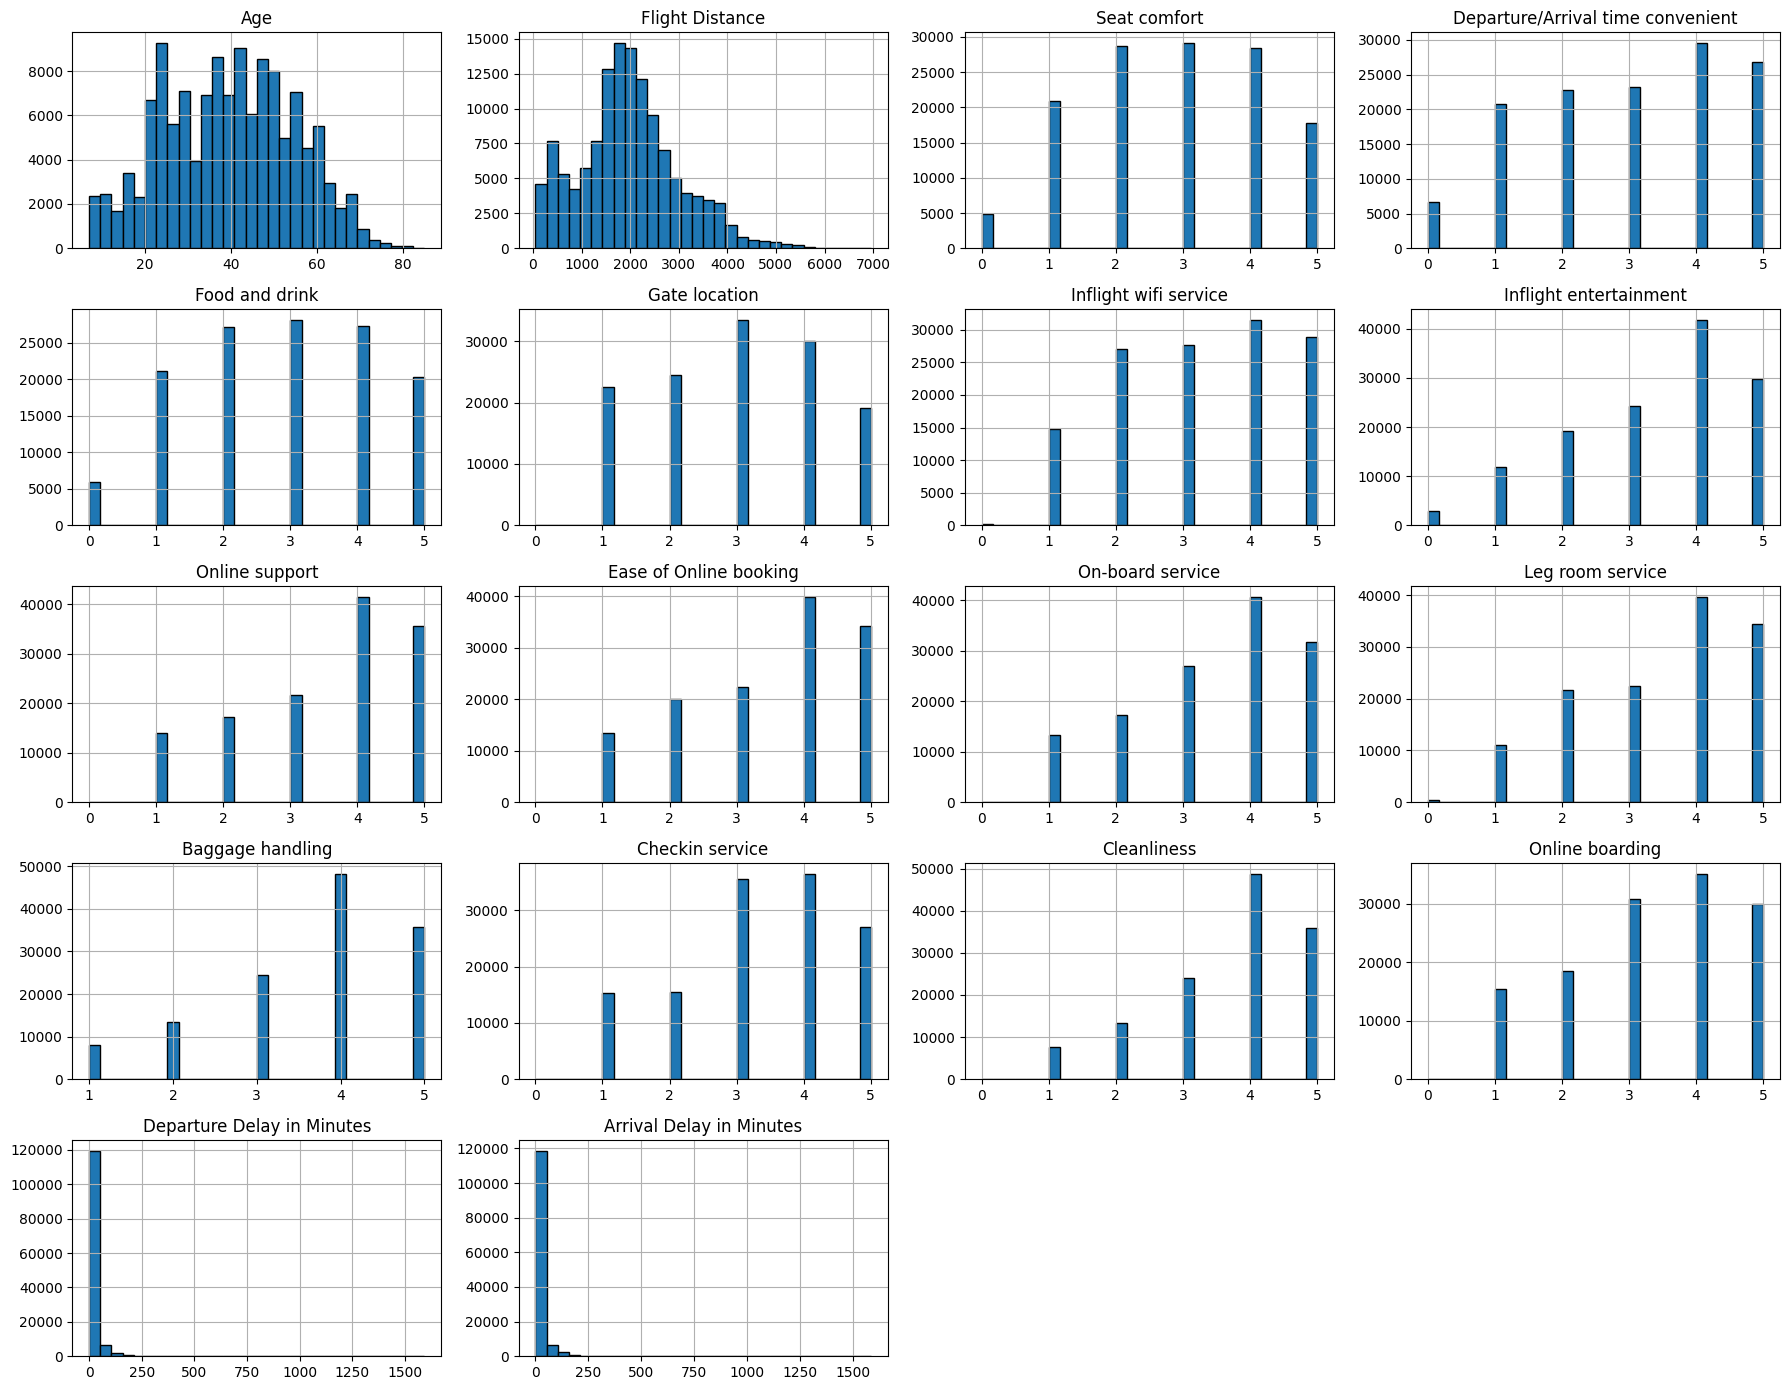

In [15]:
numeric_cols = df_new.select_dtypes(include='number').columns

df_new[numeric_cols].hist(figsize=(18, 14),bins=30,edgecolor='black')

plt.tight_layout()
plt.show()

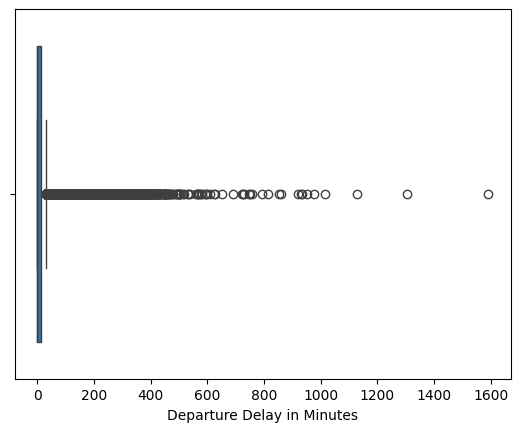

In [16]:
sns.boxplot(data=df_new,x="Departure Delay in Minutes")
plt.show()

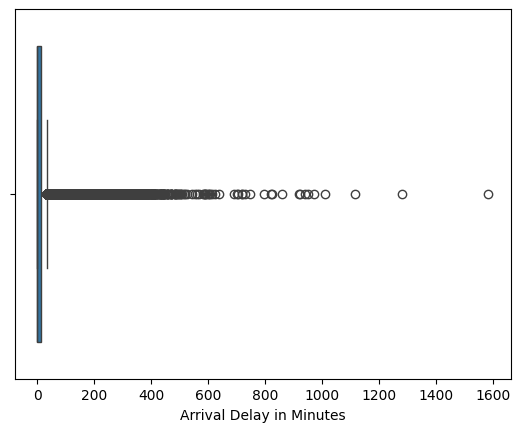

In [17]:
sns.boxplot(data=df_new,x="Arrival Delay in Minutes")
plt.show()

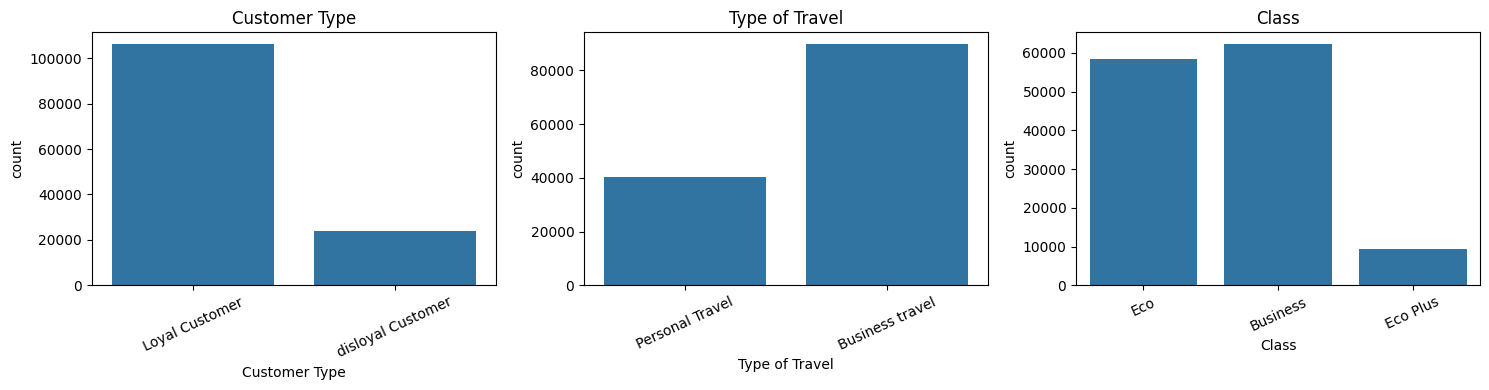

In [18]:
cat_cols = ['Customer Type','Type of Travel','Class']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for col, ax in zip(cat_cols, axes):
    sns.countplot(data=df_new, x=col, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()


###Preprocessing for Data

In [19]:

service_cols = ['Seat comfort','Departure/Arrival time convenient','Food and drink', 'Gate location','Inflight wifi service','Inflight entertainment','Online support','Ease of Online booking','On-board service','Leg room service','Baggage handling','Checkin service','Cleanliness','Online boarding']

data_copy = df_new[service_cols].copy()

print(data_copy.shape)
print(data_copy.isnull().sum().sum())
print(data_copy.dtypes)


(129880, 14)
0
Seat comfort                         int64
Departure/Arrival time convenient    int64
Food and drink                       int64
Gate location                        int64
Inflight wifi service                int64
Inflight entertainment               int64
Online support                       int64
Ease of Online booking               int64
On-board service                     int64
Leg room service                     int64
Baggage handling                     int64
Checkin service                      int64
Cleanliness                          int64
Online boarding                      int64
dtype: object


In [20]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
cluster_data=scaler.fit_transform(data_copy)
cluster_data

array([[-2.03779055, -1.9582301 , -1.97544301, ...,  1.31621673,
        -0.61276078, -1.04148541],
       [-2.03779055, -1.9582301 , -1.97544301, ..., -1.06364501,
        -0.61276078, -1.04148541],
       [-2.03779055, -1.9582301 , -1.97544301, ...,  0.52292948,
         0.25546851, -1.04148541],
       ...,
       [ 0.11586891, -1.9582301 ,  0.10251673, ..., -1.06364501,
        -0.61276078, -1.04148541],
       [ 0.11586891, -0.64865978,  0.10251673, ..., -1.06364501,
        -2.34921937, -1.04148541],
       [ 0.11586891,  0.66091053,  0.10251673, ..., -0.27035777,
        -0.61276078, -0.27149028]])

###Kmeans

In [21]:
from sklearn.cluster import KMeans
Kmeans=KMeans(n_clusters=2,random_state=42,n_init=10)
Kmeans.fit(cluster_data)


KMeans(n_clusters=2, n_init=10, random_state=42)

In [22]:
Kmeans.cluster_centers_

array([[ 0.24256531,  0.07256782,  0.13192354,  0.02632606,  0.435472  ,
         0.38982452,  0.51663534,  0.63972041,  0.38938964,  0.32527556,
         0.36388286,  0.25125362,  0.36533239,  0.52722786],
       [-0.34301801, -0.10262008, -0.18655656, -0.03722838, -0.61581245,
        -0.55126114, -0.73058767, -0.90464551, -0.55064617, -0.45998076,
        -0.51457636, -0.35530438, -0.51662617, -0.74556684]])

In [23]:
y_kmeans = Kmeans.fit_predict(cluster_data)
y_kmeans

array([1, 1, 1, ..., 1, 1, 0], dtype=int32)

In [24]:
data_copy['Cluster'] = Kmeans.labels_

In [25]:
print(pd.crosstab(data_copy['Cluster'],df['satisfaction'],margins=True))


satisfaction  dissatisfied  satisfied     All
Cluster                                      
0                    18375      57729   76104
1                    40418      13358   53776
All                  58793      71087  129880


In [26]:
data_copy.head(5)

,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,Inflight wifi service,Inflight entertainment,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Cluster
0,0,0,0,2,2,4,2,3,3,0,3,5,3,2,1
1,0,0,0,3,0,2,2,3,4,4,4,2,3,2,1
2,0,0,0,3,2,0,2,2,3,3,4,4,4,2,1
3,0,0,0,3,3,4,3,1,1,0,1,4,1,3,1
4,0,0,0,3,4,3,4,2,2,0,2,4,2,5,1


In [27]:
data_f =pd.DataFrame({"actual":df['satisfaction'],"predicted":data_copy['Cluster']})
data_f.head(5)

,actual,predicted
0,satisfied,1
1,satisfied,1
2,satisfied,1
3,satisfied,1
4,satisfied,1


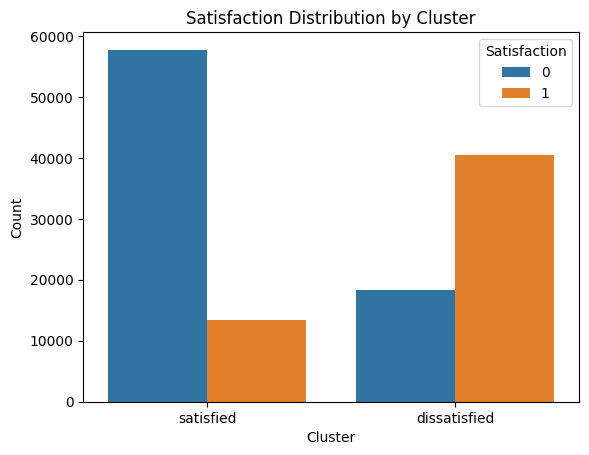

In [28]:
sns.countplot(data=data_f,x="actual",hue="predicted")
plt.title('Satisfaction Distribution by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Count')
plt.legend(title='Satisfaction')
plt.show()

In [47]:
y_true = df['satisfaction'].map({ 'satisfied': 1,'dissatisfied': 0})
y_pred = data_copy['Cluster'].map({0: 1,1: 0})
data_f = pd.DataFrame({'actual': y_true, 'predicted': y_pred})
data_f.tail(15)

,actual,predicted
129865,1,0
129866,1,1
129867,1,1
129868,1,0
129869,1,0
129870,1,1
129871,1,0
129872,1,1
129873,1,1
129874,1,0


In [48]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
confusion_matrix = confusion_matrix(data_f['actual'], data_f['predicted'])
print(confusion_matrix)
accuracy_score = accuracy_score(data_f['actual'], data_f['predicted'])
print(accuracy_score)
classification_report = classification_report(data_f['actual'], data_f['predicted'])
print(classification_report)


[[40418 18375]
 [13358 57729]]
0.7556744687403757
              precision    recall  f1-score   support

           0       0.75      0.69      0.72     58793
           1       0.76      0.81      0.78     71087

    accuracy                           0.76    129880
   macro avg       0.76      0.75      0.75    129880
weighted avg       0.76      0.76      0.75    129880



###Agglomerative Clustering

In [34]:
np.random.seed(42)
sample_idx = np.random.choice(len(cluster_data),size=5000, replace=False)
X_sample = cluster_data[sample_idx]
satisfaction_sample = df['satisfaction'].iloc[sample_idx]

In [36]:
from sklearn.cluster import AgglomerativeClustering
agg=AgglomerativeClustering(n_clusters=2,metric='euclidean',linkage='ward')
labels = agg.fit_predict(X_sample)

In [42]:
result = pd.DataFrame({'actual': satisfaction_sample, 'predicted': labels})
print(pd.crosstab(result['actual'],result['predicted'],margins=True))

predicted        0     1   All
actual                        
dissatisfied  1939   372  2311
satisfied      864  1825  2689
All           2803  2197  5000


In [43]:
result.head(10)

,actual,predicted
103044,satisfied,1
43282,dissatisfied,0
65543,satisfied,1
65083,satisfied,0
76496,dissatisfied,0
78319,dissatisfied,1
43712,dissatisfied,0
8092,satisfied,0
105253,satisfied,1
71027,dissatisfied,0


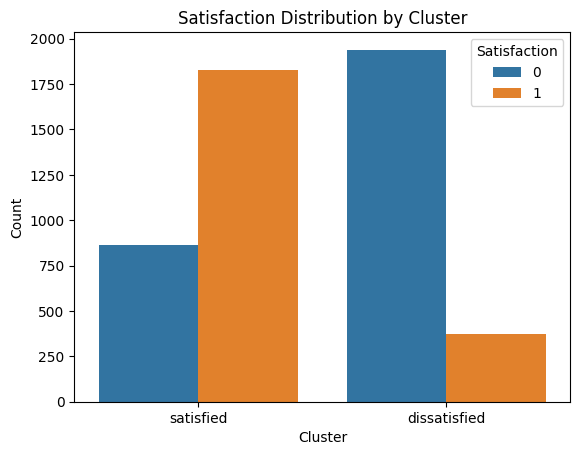

In [46]:
sns.countplot(data=result,x="actual",hue="predicted")
plt.title('Satisfaction Distribution by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Count')
plt.legend(title='Satisfaction')
plt.show()

In [49]:
y_true = df['satisfaction'].map({ 'satisfied': 1,'dissatisfied': 0})
result = pd.DataFrame({'actual': y_true, 'predicted': y_pred})
result.tail(15)

,actual,predicted
129865,1,0
129866,1,1
129867,1,1
129868,1,0
129869,1,0
129870,1,1
129871,1,0
129872,1,1
129873,1,1
129874,1,0


In [50]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
confusion_matrix = confusion_matrix(result['actual'], result['predicted'])
print(confusion_matrix)
accuracy_score = accuracy_score(result['actual'], result['predicted'])
print(accuracy_score)
classification_report = classification_report(result['actual'], result['predicted'])
print(classification_report)


[[40418 18375]
 [13358 57729]]
0.7556744687403757
              precision    recall  f1-score   support

           0       0.75      0.69      0.72     58793
           1       0.76      0.81      0.78     71087

    accuracy                           0.76    129880
   macro avg       0.76      0.75      0.75    129880
weighted avg       0.76      0.76      0.75    129880

